In [ ]:
# Colab already has torch. We only add the Hugging Face tooling we need.
!pip install -q transformers datasets evaluate rouge_score bert_score sentencepiece accelerate

import torch, transformers
print("torch:", torch.__version__)
print("transformers:", transformers.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 6.9 MB/s eta 0:00:00
torch: 2.11.0+cu130
transformers: 5.18.0
GPU available: True
GPU: Tesla T4


In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

MODEL_NAME = "sshleifer/distilbart-cnn-12-6"   # small, fast starting model
device = "cuda" if torch.cuda.is_available() else "cpu"

# Tokenizer: converts text <-> token IDs
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Model: downloads weights on first run (~1.2 GB), then moves to the GPU
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(device)
model.eval()   # inference mode: turns off dropout so output is stable

print("Model loaded on:", device)

config.json:   0%|          | 0.00/1.80k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.22GB            

...

[transformers] Please make sure the generation config includes `forced_bos_token_id=0`. 


Loading weights:   0%|          | 0/358 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.22GB            

model.safetensors: downloading bytes:           |  0.00B            

Model loaded on: cuda


In [ ]:
def summarize(text, max_length=60, min_length=20, num_beams=4):
    # Convert text to tensors; truncate anything beyond BART's 1024-token limit
    inputs = tokenizer(text, return_tensors="pt",
                       truncation=True, max_length=1024).to(device)

    with torch.no_grad():                      # no gradients needed for inference
        output_ids = model.generate(
            **inputs,
            max_length=max_length,             # upper bound on summary tokens
            min_length=min_length,             # prevents one-line summaries
            num_beams=4,                       # beam search: keeps 4 candidates, better quality
            early_stopping=True,
        )
    return tokenizer.decode(output_ids[0], skip_special_tokens=True)


SAMPLE_TEXT = """
The James Webb Space Telescope, launched in December 2021, is the largest and most
powerful space telescope ever built. It observes the universe in infrared light,
which allows it to see through cosmic dust and detect some of the earliest galaxies
formed after the Big Bang. Since beginning science operations in 2022, it has
returned detailed images of distant galaxies, star-forming regions, and the
atmospheres of planets orbiting other stars. Astronomers say the data is already
challenging existing models of how quickly galaxies formed in the early universe.
The telescope orbits the Sun about 1.5 million kilometers from Earth, at a point
called L2, where its sunshield keeps its instruments extremely cold.
"""

n_tokens = len(tokenizer(SAMPLE_TEXT)["input_ids"])
print(f"Input length: {n_tokens} tokens (limit: 1024)")
print("SUMMARY:", summarize(SAMPLE_TEXT))

Input length: 149 tokens (limit: 1024)
SUMMARY:  James Webb Space Telescope is the largest and most powerful space telescope ever built . It observes the universe in infrared light, which allows it to see through cosmic dust and detect some of the earliest galaxies after the Big Bang .


In [ ]:
import re, unicodedata

def postprocess(summary):
    # CNN/DM models emit " ." with a space before punctuation; remove it
    summary = re.sub(r"\s+([.,;:!?])", r"\1", summary)
    return summary.strip()

def summarize(text, max_length=60, min_length=20, num_beams=4):
    inputs = tokenizer(text, return_tensors="pt",
                       truncation=True, max_length=1024).to(device)
    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_length=max_length,
            min_length=min_length,
            num_beams=num_beams,        # fixed: now actually uses the parameter
            early_stopping=True,
        )
    return postprocess(tokenizer.decode(output_ids[0], skip_special_tokens=True))

print(summarize(SAMPLE_TEXT))   # should now read "...Big Bang." with no stray space

James Webb Space Telescope is the largest and most powerful space telescope ever built. It observes the universe in infrared light, which allows it to see through cosmic dust and detect some of the earliest galaxies after the Big Bang.


In [ ]:
def clean_text(text):
    text = unicodedata.normalize("NFKC", text)             # unify odd unicode characters
    text = re.sub(r"https?://\S+", "", text)               # remove URLs
    # remove dateline boilerplate such as "LONDON, England (CNN) -- "
    text = re.sub(r"^.{0,80}?\(CNN\)\s*(?:--|-)?\s*", "", text, count=1)
    text = re.sub(r"\s+", " ", text)                       # collapse whitespace/newlines
    return text.strip()

def count_tokens(text):
    return len(tokenizer(text, add_special_tokens=False)["input_ids"])

def split_sentences(text):
    # Simple regex splitter: split after . ! ? followed by whitespace.
    # Known limitation: can mis-split abbreviations like "U.S. Army". Fine for this project.
    return [s.strip() for s in re.split(r"(?<=[.!?])\s+", text) if s.strip()]

In [ ]:
def chunk_text(text, max_tokens=900):
    chunks, current, current_len = [], [], 0
    for sent in split_sentences(text):
        n = count_tokens(sent)

        # Edge case: a single sentence longer than the limit -> hard split by tokens
        if n > max_tokens:
            if current:
                chunks.append(" ".join(current)); current, current_len = [], 0
            ids = tokenizer(sent, add_special_tokens=False)["input_ids"]
            for i in range(0, len(ids), max_tokens):
                chunks.append(tokenizer.decode(ids[i:i + max_tokens]))
            continue

        # Current chunk is full -> close it and start a new one
        if current_len + n > max_tokens:
            chunks.append(" ".join(current)); current, current_len = [], 0

        current.append(sent)
        current_len += n

    if current:
        chunks.append(" ".join(current))
    return chunks

In [ ]:
def summarize_long(text, chunk_tokens=900, chunk_summary_len=80,
                   final_max_length=150, final_min_length=40,
                   depth=0, verbose=True):
    text = clean_text(text)

    # Base case: fits in one pass (or we recursed too deep, so truncate as a safeguard)
    if count_tokens(text) <= 1000 or depth >= 4:
        return summarize(text, max_length=final_max_length, min_length=final_min_length)

    chunks = chunk_text(text, chunk_tokens)                       # SPLIT
    if verbose:
        print(f"[level {depth}] {count_tokens(text)} tokens -> {len(chunks)} chunks")

    partials = [summarize(c, max_length=chunk_summary_len, min_length=20)   # MAP
                for c in chunks]

    combined = " ".join(partials)                                 # REDUCE
    return summarize_long(combined, chunk_tokens, chunk_summary_len,
                          final_max_length, final_min_length, depth + 1, verbose)

In [ ]:
from datasets import load_dataset
import time

ds = load_dataset("abisee/cnn_dailymail", "3.0.0", split="test[:6]")
long_doc = "\n\n".join(ds["article"])
print("Long document:", count_tokens(long_doc), "tokens")

# A) Naive: model silently truncates to the first 1024 tokens
t0 = time.time()
naive = summarize(clean_text(long_doc), max_length=150, min_length=40)
print(f"\nNAIVE (truncated), {time.time()-t0:.1f}s:\n{naive}")

# B) Map-reduce
t0 = time.time()
chunked = summarize_long(long_doc)
print(f"\nCHUNKED (map-reduce), {time.time()-t0:.1f}s:\n{chunked}")

# Safety check: no chunk may exceed the model limit
chunks = chunk_text(clean_text(long_doc))
sizes = [count_tokens(c) for c in chunks]
print("\nChunk sizes:", sizes)
assert max(sizes) <= 1024, "A chunk is too long!"

README.md:   0%|          | 0.00/15.6k [00:00<?, ?B/s]

3.0.0/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  257MB            

3.0.0/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

3.0.0/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  257MB            

3.0.0/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

...

Generating train split:   0%|          | 0/287113 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/13368 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/11490 [00:00<?, ? examples/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (3319 > 1024). Running this sequence through the model will result in indexing errors


Long document: 3319 tokens

NAIVE (truncated), 0.7s:
Palestinian Authority officially becomes 123rd member of the International Criminal Court. The move gives the court jurisdiction over alleged crimes in Palestinian territories. Israel and the United States opposed the Palestinians' efforts to join the court.
[level 0] 3304 tokens -> 4 chunks

CHUNKED (map-reduce), 3.2s:
Theia suffered a dislocated jaw, leg injuries and a caved-in sinus cavity. She still requires surgery to help her breathe. The International Criminal Court was set up in 2002 to prosecute genocide, crimes against humanity and war crimes.

Chunk sizes: [866, 847, 893, 698]


In [ ]:
import pandas as pd, numpy as np, time, gc
from datasets import load_dataset

N_SAMPLES = 100     # raise to 200 later if time allows
SEED = 42

MODELS = {
    "distilbart-cnn-12-6":   "sshleifer/distilbart-cnn-12-6",
    "bart-large-cnn":        "facebook/bart-large-cnn",
    "pegasus-cnn_dailymail": "google/pegasus-cnn_dailymail",
}

# Identical for every model so the comparison is fair
GEN_KWARGS = dict(max_length=142, min_length=56, num_beams=4,
                  length_penalty=2.0, no_repeat_ngram_size=3, early_stopping=True)

test_ds = load_dataset("abisee/cnn_dailymail", "3.0.0", split="test")
eval_ds = test_ds.shuffle(seed=SEED).select(range(N_SAMPLES))   # reproducible random sample

articles   = [clean_text(a) for a in eval_ds["article"]]
references = [h.replace("\n", " ") for h in eval_ds["highlights"]]  # human-written summaries
print(len(articles), "articles ready")

100 articles ready


In [ ]:
def postprocess(summary):
    summary = summary.replace("<n>", " ")                  # Pegasus newline token
    summary = re.sub(r"\s+([.,;:!?])", r"\1", summary)     # space before punctuation
    return re.sub(r"\s+", " ", summary).strip()

In [ ]:
import evaluate
from bert_score import BERTScorer

rouge = evaluate.load("rouge")
# Loads roberta-large once (~1.4 GB). rescale_with_baseline spreads scores out
# so they are easier to interpret (raw BERTScores all cluster near 0.85-0.9).
bert_scorer = BERTScorer(lang="en", rescale_with_baseline=True)

def compute_metrics(predictions, references, sources):
    r = rouge.compute(predictions=predictions, references=references, use_stemmer=True)
    _, _, F1 = bert_scorer.score(predictions, references)
    compression = np.mean([len(p.split()) / max(len(s.split()), 1)
                           for p, s in zip(predictions, sources)])
    return {"rouge1": float(r["rouge1"]), "rouge2": float(r["rouge2"]),
            "rougeL": float(r["rougeL"]), "bertscore_f1": F1.mean().item(),
            "compression_ratio": float(compression)}

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
def run_model(hf_name, texts, **gen_kwargs):
    tok = AutoTokenizer.from_pretrained(hf_name)
    mdl = AutoModelForSeq2SeqLM.from_pretrained(hf_name).to(device).eval()

    def gen(text):
        inputs = tok(text, return_tensors="pt", truncation=True, max_length=1024).to(device)
        with torch.no_grad():
            ids = mdl.generate(**inputs, **gen_kwargs)
        return postprocess(tok.decode(ids[0], skip_special_tokens=True))

    gen(texts[0])                                  # warm-up: first call is always slower
    preds, times = [], []
    for t in texts:
        if device == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        preds.append(gen(t))
        if device == "cuda": torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)

    del mdl, tok                                   # free GPU memory before the next model
    gc.collect(); torch.cuda.empty_cache()
    return preds, float(np.mean(times))

In [ ]:
preds, lat = run_model(MODELS["distilbart-cnn-12-6"], articles[:20], **GEN_KWARGS)
print("Latency/doc:", round(lat, 2), "s\n")
print("EXAMPLE SUMMARY:\n", preds[0], "\n")
print("REFERENCE:\n", references[0], "\n")
print(compute_metrics(preds, references[:20], articles[:20]))

Loading weights:   0%|          | 0/358 [00:00<?, ?it/s]

Latency/doc: 1.07 s

EXAMPLE SUMMARY:
 John Sutter: I see signs of a medical marijuana revolution everywhere. He says 53% of Americans favor its legalization, with 77% supporting it for medical purposes. Sutter says it's burning white hot among young people, but also shows up among parents and grandparents in his kids' school. "Weed 3" will show the first federally approved clinical study on the use of marijuana for PTSD. 

REFERENCE:
 CNN's Dr. Sanjay Gupta says we should legalize medical marijuana now . He says he knows how easy it is do nothing "because I did nothing for too long" 

{'rouge1': np.float64(0.42706045909059925), 'rouge2': np.float64(0.1921227869847288), 'rougeL': np.float64(0.2906608432561592), 'bertscore_f1': 0.29951757192611694, 'compression_ratio': np.float64(0.11726757519435956)}


In [ ]:
results, all_preds = [], {}
for short, hf in MODELS.items():
    print("Running", short, "...")
    preds, lat = run_model(hf, articles, **GEN_KWARGS)
    all_preds[short] = preds
    m = compute_metrics(preds, references, articles)
    m.update({"model": short, "mean_latency_s": lat, "n_samples": len(articles)})
    results.append(m)

df = pd.DataFrame(results).set_index("model")
df[["rouge1", "rouge2", "rougeL"]] *= 100       # report ROUGE as percentages
df = df.round(3)
display(df)

Running distilbart-cnn-12-6 ...


Loading weights:   0%|          | 0/358 [00:00<?, ?it/s]

Running bart-large-cnn ...


config.json:   0%|          | 0.00/1.58k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/680 [00:00<?, ?it/s]

[transformers] PegasusForConditionalGeneration LOAD REPORT from: google/pegasus-cnn_dailymail
Key                                  | Status  | 
-------------------------------------+---------+-
model.encoder.embed_positions.weight | MISSING | 
model.decoder.embed_positions.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


generation_config.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

,rouge1,rouge2,rougeL,bertscore_f1,compression_ratio,mean_latency_s,n_samples
model,,,,,,,
distilbart-cnn-12-6,44.417,20.928,29.690,0.307,0.129,1.043,100
bart-large-cnn,43.991,21.275,30.582,0.302,0.122,1.458,100
pegasus-cnn_dailymail,44.349,20.189,30.637,0.314,0.101,1.705,100


In [ ]:
from google.colab import files

df.to_csv("metrics.csv")
pred_df = pd.DataFrame(all_preds)
pred_df.insert(0, "article", articles)
pred_df.insert(1, "reference", references)
pred_df.to_csv("predictions.csv", index=False)

files.download("metrics.csv")
files.download("predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
N = len(articles)
per_sample = {}

for name, preds in all_preds.items():
    # use_aggregator=False -> one score per article instead of an average
    r = rouge.compute(predictions=preds, references=references,
                      use_stemmer=True, use_aggregator=False)
    _, _, F1 = bert_scorer.score(preds, references)
    per_sample[name] = {
        "rouge1": np.array(r["rouge1"]) * 100,
        "rouge2": np.array(r["rouge2"]) * 100,
        "rougeL": np.array(r["rougeL"]) * 100,
        "bertscore_f1": F1.cpu().numpy(),
    }

# Sanity check: these means should match the Cell 14 table within ~0.1
for name in per_sample:
    print(name, round(per_sample[name]["rouge1"].mean(), 3))

distilbart-cnn-12-6 44.391
bart-large-cnn 43.986
pegasus-cnn_dailymail 44.318


In [ ]:
rng = np.random.default_rng(SEED)
B = 10_000
idx = rng.integers(0, N, size=(B, N))   # one set of resamples, reused for every model -> paired

METRICS = ["rouge1", "rouge2", "rougeL", "bertscore_f1"]

# 95% CI of each model's mean score
rows = []
for name in per_sample:
    for m in METRICS:
        x = per_sample[name][m]
        lo, hi = np.percentile(x[idx].mean(axis=1), [2.5, 97.5])
        rows.append({"model": name, "metric": m, "mean": x.mean(), "ci_low": lo, "ci_high": hi})
ci_df = pd.DataFrame(rows).round(3)
display(ci_df)

# Paired differences: is model A really different from model B?
names = list(per_sample)
diff_rows = []
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        a, b = names[i], names[j]
        for m in METRICS:
            d = per_sample[a][m][idx].mean(axis=1) - per_sample[b][m][idx].mean(axis=1)
            lo, hi = np.percentile(d, [2.5, 97.5])
            diff_rows.append({"A": a, "B": b, "metric": m,
                              "diff (A-B)": (per_sample[a][m] - per_sample[b][m]).mean(),
                              "ci_low": lo, "ci_high": hi,
                              "significant": not (lo <= 0 <= hi)})
diff_df = pd.DataFrame(diff_rows).round(3)
display(diff_df)

# Context: summary length vs the human reference length
ref_words = np.mean([len(r.split()) for r in references])
print("\nReference avg words:", round(ref_words, 1))
for n_, p in all_preds.items():
    print(n_, "avg words:", round(np.mean([len(s.split()) for s in p]), 1))

,model,metric,mean,ci_low,ci_high
0,distilbart-cnn-12-6,rouge1,44.391,42.071,46.659
1,distilbart-cnn-12-6,rouge2,20.884,18.594,23.203
2,distilbart-cnn-12-6,rougeL,29.697,27.495,31.885
3,distilbart-cnn-12-6,bertscore_f1,0.307,0.282,0.333
4,bart-large-cnn,rouge1,43.986,41.471,46.502
5,bart-large-cnn,rouge2,21.262,18.735,23.896
6,bart-large-cnn,rougeL,30.569,28.241,32.957
7,bart-large-cnn,bertscore_f1,0.302,0.277,0.328
8,pegasus-cnn_dailymail,rouge1,44.318,41.988,46.646
9,pegasus-cnn_dailymail,rouge2,20.119,17.663,22.676


,A,B,metric,diff (A-B),ci_low,ci_high,significant
0,distilbart-cnn-12-6,bart-large-cnn,rouge1,0.405,-1.242,2.123,False
1,distilbart-cnn-12-6,bart-large-cnn,rouge2,-0.378,-1.803,1.071,False
2,distilbart-cnn-12-6,bart-large-cnn,rougeL,-0.873,-2.504,0.724,False
3,distilbart-cnn-12-6,bart-large-cnn,bertscore_f1,0.005,-0.014,0.023,False
4,distilbart-cnn-12-6,pegasus-cnn_dailymail,rouge1,0.073,-1.925,2.062,False
5,distilbart-cnn-12-6,pegasus-cnn_dailymail,rouge2,0.765,-1.135,2.576,False
6,distilbart-cnn-12-6,pegasus-cnn_dailymail,rougeL,-0.908,-3.057,1.195,False
7,distilbart-cnn-12-6,pegasus-cnn_dailymail,bertscore_f1,-0.007,-0.029,0.015,False
8,bart-large-cnn,pegasus-cnn_dailymail,rouge1,-0.332,-2.489,1.919,False
9,bart-large-cnn,pegasus-cnn_dailymail,rouge2,1.143,-0.938,3.277,False



Reference avg words: 53.2
distilbart-cnn-12-6 avg words: 67.1
bart-large-cnn avg words: 63.0
pegasus-cnn_dailymail avg words: 50.8


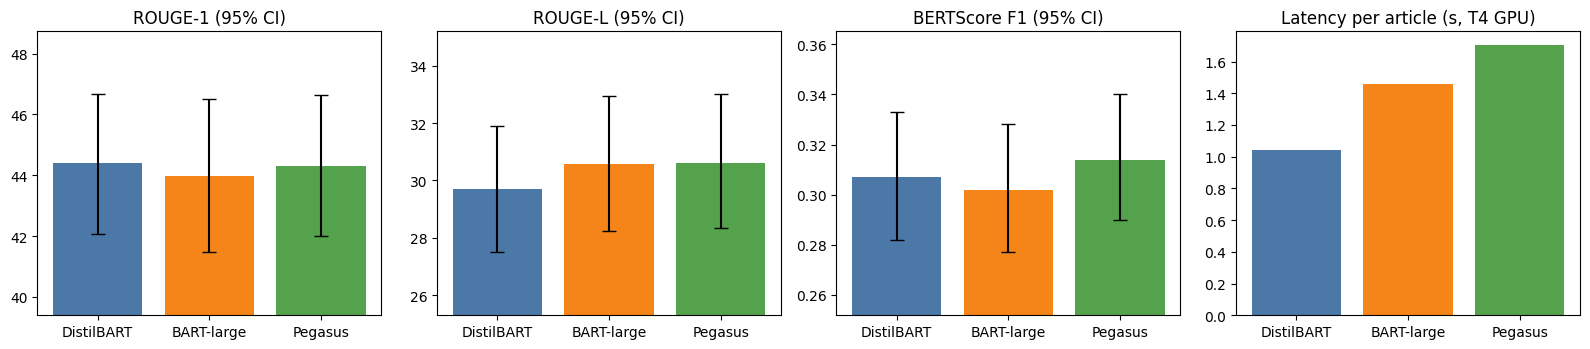

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
colors = ["#4C78A8", "#F58518", "#54A24B"]
panels = [("rouge1", "ROUGE-1"), ("rougeL", "ROUGE-L"), ("bertscore_f1", "BERTScore F1")]

for ax, (m, title) in zip(axes[:3], panels):
    sub = ci_df[ci_df.metric == m].set_index("model").loc[names]
    err = [sub["mean"] - sub["ci_low"], sub["ci_high"] - sub["mean"]]
    ax.bar(names, sub["mean"], yerr=err, capsize=5, color=colors)
    ax.set_title(title + " (95% CI)")
    ax.set_xticks(range(len(names))); ax.set_xticklabels(["DistilBART", "BART-large", "Pegasus"])
    lo_, hi_ = (sub["ci_low"].min(), sub["ci_high"].max()); pad = (hi_ - lo_) * 0.4
    ax.set_ylim(lo_ - pad, hi_ + pad)   # zoomed axis; the CI bars show how much overlap there is

lat = df["mean_latency_s"].loc[names]
axes[3].bar(["DistilBART", "BART-large", "Pegasus"], lat, color=colors)
axes[3].set_title("Latency per article (s, T4 GPU)")

plt.tight_layout()
plt.savefig("benchmark.png", dpi=200)
plt.show()
files.download("benchmark.png")
ci_df.to_csv("confidence_intervals.csv", index=False)
diff_df.to_csv("pairwise_differences.csv", index=False)
files.download("confidence_intervals.csv"); files.download("pairwise_differences.csv")

In [ ]:
# Our summarize()/count_tokens() use the global tokenizer/model, so switch them
# to bart-large-cnn (the standard baseline) and free the old model.
model = None; gc.collect(); torch.cuda.empty_cache()
MODEL_NAME = MODELS["bart-large-cnn"]
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(device).eval()

bills = load_dataset("FiscalNote/billsum", split="test").shuffle(seed=SEED)

N_LONG = 50
long_docs, long_refs = [], []
for ex in bills:
    text = clean_text(ex["text"].replace("<all>", ""))   # "<all>" is a dataset artifact
    if 1500 <= count_tokens(text) <= 6000:               # long enough that chunking matters
        long_docs.append(text)
        long_refs.append(ex["summary"].replace("\n", " "))
    if len(long_docs) == N_LONG:
        break

lens = [count_tokens(d) for d in long_docs]
print(len(long_docs), "bills | tokens min/median/max:", min(lens), int(np.median(lens)), max(lens))
print("Reference avg words:", round(np.mean([len(r.split()) for r in long_refs]), 1))

Loading weights:   0%|          | 0/511 [00:00<?, ?it/s]

README.md:   0%|          | 0.00/7.27k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 91.8MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 15.8MB            

...

data/ca_test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/18949 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3269 [00:00<?, ? examples/s]

Generating ca_test split:   0%|          | 0/1237 [00:00<?, ? examples/s]

50 bills | tokens min/median/max: 1508 1999 3685
Reference avg words: 161.5


In [ ]:
FINAL_MAX, FINAL_MIN = 200, 80    # identical for both strategies -> fair comparison

def timed(fn, *args, **kw):
    if device == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    out = fn(*args, **kw)
    if device == "cuda": torch.cuda.synchronize()
    return out, time.perf_counter() - t0

# warm-up so the first timed call isn't penalized
summarize_long(long_docs[0], final_max_length=FINAL_MAX, final_min_length=FINAL_MIN, verbose=False)

trunc_preds, trunc_t, chunk_preds, chunk_t = [], [], [], []
for i, doc in enumerate(long_docs):
    p, t = timed(summarize, doc, max_length=FINAL_MAX, min_length=FINAL_MIN)   # silently truncates
    trunc_preds.append(p); trunc_t.append(t)
    p, t = timed(summarize_long, doc, final_max_length=FINAL_MAX,
                 final_min_length=FINAL_MIN, verbose=False)                    # map-reduce
    chunk_preds.append(p); chunk_t.append(t)
    if (i + 1) % 10 == 0: print(f"{i+1}/{N_LONG} done")

10/50 done
20/50 done
30/50 done
40/50 done
50/50 done


In [ ]:
def per_doc_scores(preds, refs):
    r = rouge.compute(predictions=preds, references=refs, use_stemmer=True, use_aggregator=False)
    _, _, F1 = bert_scorer.score(preds, refs)
    return {"rouge1": np.array(r["rouge1"]) * 100, "rouge2": np.array(r["rouge2"]) * 100,
            "rougeL": np.array(r["rougeL"]) * 100, "bertscore_f1": F1.cpu().numpy()}

S_trunc = per_doc_scores(trunc_preds, long_refs)
S_chunk = per_doc_scores(chunk_preds, long_refs)

rng = np.random.default_rng(SEED)
idx_long = rng.integers(0, N_LONG, size=(10_000, N_LONG))

rows = []
for m in METRICS:
    d = S_chunk[m] - S_trunc[m]                           # per-bill difference, chunked minus truncated
    lo, hi = np.percentile(d[idx_long].mean(axis=1), [2.5, 97.5])
    rows.append({"metric": m, "truncated": S_trunc[m].mean(), "chunked": S_chunk[m].mean(),
                 "diff": d.mean(), "ci_low": lo, "ci_high": hi, "significant": not (lo <= 0 <= hi)})
long_df = pd.DataFrame(rows).round(3)
display(long_df)

wc = lambda xs: round(np.mean([len(x.split()) for x in xs]), 1)
print("\nAvg words | reference:", wc(long_refs), "| truncated:", wc(trunc_preds), "| chunked:", wc(chunk_preds))
print("Latency/doc | truncated:", round(np.mean(trunc_t), 2), "s | chunked:", round(np.mean(chunk_t), 2), "s")

# One example for the error analysis on Day 6
print("\nREFERENCE:\n", long_refs[0][:600], "\n\nTRUNCATED:\n", trunc_preds[0], "\n\nCHUNKED:\n", chunk_preds[0])

,metric,truncated,chunked,diff,ci_low,ci_high,significant
0,rouge1,34.761,34.124,-0.637,-2.920,1.505,False
1,rouge2,16.141,13.841,-2.301,-4.740,-0.081,True
2,rougeL,23.832,22.474,-1.358,-3.679,0.774,False
3,bertscore_f1,0.095,0.080,-0.016,-0.045,0.012,False



Avg words | reference: 161.5 | truncated: 74.3 | chunked: 75.0
Latency/doc | truncated: 1.95 s | chunked: 5.21 s

REFERENCE:
 HIV Nondiscrimination in Travel and Immigration Act of 2007 - Amends the Immigration and Nationality Act to eliminate the human immunodeficiency virus (HIV) bar to U.S. admission.  Directs the Secretary of Health and Human Services to: (1) convene a panel of public health experts to review immigration policies regarding HIV as a communicable disease of public health significance (and thus a health-related ground for inadmissibility); and (2) make a determination and report to Congress regarding the continued listing of HIV as a health-related ground for inadmissibility. 

TRUNCATED:
 Under Federal immigration law, prospective immigrants, foreign students, refugees, and tourists who are infected with the Human Immunodeficiency Virus (HIV) are prohibited from entering the United States. Applicants for permanent residence and refugee status are required to be test

In [ ]:
long_df.to_csv("long_doc_results.csv", index=False)
pd.DataFrame({"document": long_docs, "reference": long_refs,
              "truncated": trunc_preds, "chunked": chunk_preds}).to_csv("long_doc_predictions.csv", index=False)
files.download("long_doc_results.csv"); files.download("long_doc_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
def toks(t): return re.findall(r"[a-z0-9']+", t.lower())

def novel_bigram_rate(summary, source):
    # Fraction of summary bigrams NOT in the source: 0 = pure copying, higher = more abstractive
    s, src = toks(summary), toks(source)
    s_bi, src_bi = list(zip(s, s[1:])), set(zip(src, src[1:]))
    return float(np.mean([b not in src_bi for b in s_bi])) if s_bi else 0.0

def unsupported_numbers(summary, source):
    src = source.lower()
    return [n for n in re.findall(r"\d[\d,.]*", summary) if n.strip(".,") not in src]

def unsupported_entities(summary, source):
    # Crude proper-noun proxy: capitalized, non-sentence-initial words absent from the source
    src, out = source.lower(), []
    for sent in re.split(r"(?<=[.!?])\s+", summary):
        words = re.findall(r"[A-Za-z][A-Za-z'-]*", sent)
        out += [w for w in words[1:] if w[0].isupper() and len(w) > 2 and w.lower() not in src]
    return out

systems = {**{f"CNN/DM | {k}": (v, articles) for k, v in all_preds.items()},
           "BillSum | truncated": (trunc_preds, long_docs),
           "BillSum | chunked":   (chunk_preds, long_docs)}

rows, flagged = [], {}
for name, (preds, srcs) in systems.items():
    nums = [unsupported_numbers(p, s) for p, s in zip(preds, srcs)]
    ents = [unsupported_entities(p, s) for p, s in zip(preds, srcs)]
    flagged[name] = (nums, ents)
    rows.append({"system": name,
                 "novel_bigram_%": 100 * np.mean([novel_bigram_rate(p, s) for p, s in zip(preds, srcs)]),
                 "with_unsupported_number_%": 100 * np.mean([len(x) > 0 for x in nums]),
                 "with_unsupported_entity_%": 100 * np.mean([len(x) > 0 for x in ents])})
audit_df = pd.DataFrame(rows).set_index("system").round(1)
display(audit_df)
audit_df.to_csv("audit.csv"); files.download("audit.csv")

,novel_bigram_%,with_unsupported_number_%,with_unsupported_entity_%
system,,,
CNN/DM | distilbart-cnn-12-6,13.2,0.0,10.0
CNN/DM | bart-large-cnn,10.6,0.0,8.0
CNN/DM | pegasus-cnn_dailymail,21.5,2.0,13.0
BillSum | truncated,11.2,6.0,14.0
BillSum | chunked,9.3,2.0,4.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# 1) Who is actually speaking in articles[0]?
a0 = articles[0]
print("Mentions -> Gupta:", len(re.findall("Gupta", a0)), "| Sutter:", len(re.findall("Sutter", a0)))
print(a0[:1200], "\n")

# 2) Eight random CNN/DM examples for bart-large-cnn
picks = np.random.default_rng(7).choice(N_SAMPLES, 8, replace=False)
nums_f, ents_f = flagged["CNN/DM | bart-large-cnn"]
for i in picks:
    print(f"\n=== Article {i} ===")
    print("SOURCE (start):", articles[i][:700], "...")
    print("REFERENCE:", references[i])
    print("BART-LARGE:", all_preds["bart-large-cnn"][i])
    print("Unsupported numbers:", nums_f[i], "| entities:", ents_f[i])

Mentions -> Gupta: 0 | Sutter: 0
I see signs of a revolution everywhere. I see it in the op-ed pages of the newspapers, and on the state ballots in nearly half the country. I see it in politicians who once preferred to play it safe with this explosive issue but are now willing to stake their political futures on it. I see the revolution in the eyes of sterling scientists, previously reluctant to dip a toe into this heavily stigmatized world, who are diving in head first. I see it in the new surgeon general who cites data showing just how helpful it can be. I see a revolution in the attitudes of everyday Americans. For the first time a majority, 53%, favor its legalization, with 77% supporting it for medical purposes. Support for legalization has risen 11 points in the past few years alone. In 1969, the first time Pew asked the question about legalization, only 12% of the nation was in favor. I see a revolution that is burning white hot among young people, but also shows up among the pa

In [ ]:
# Baseline: just copy the first 3 sentences. Shows how much the models add over copying.
lead3 = [" ".join(split_sentences(a)[:3]) for a in articles]
print("Lead-3:", compute_metrics(lead3, references, articles))

# Claims I could not verify from the visible text: prints context, or says NOT FOUND
def show(article, kw, width=200):
    m = re.search(kw, article, flags=re.I)
    if m:
        s = max(0, m.start() - width)
        print(f"[{kw}] ...{article[s:m.end() + width]}...\n")
    else:
        print(f"[{kw}] NOT FOUND\n")

show(articles[0], "Weed 3");        show(articles[0], "PTSD")
show(articles[56], "rescued")
show(articles[87], "Cape Town");    show(articles[87], "£21|£29")
show(articles[76], "unbelievable"); show(articles[76], "dream")
show(articles[82], "George North"); show(articles[82], r"19 games")
show(articles[22], "contact shoe"); show(articles[58], "Friday")

# Which systems have flagged entities or numbers, and where?
for name in ["CNN/DM | distilbart-cnn-12-6", "CNN/DM | bart-large-cnn", "CNN/DM | pegasus-cnn_dailymail"]:
    nums, ents = flagged[name]
    hits = [i for i in range(N_SAMPLES) if ents[i] or nums[i]]
    print(name, "->", len(hits), "flagged of", N_SAMPLES)
    for i in hits[:5]:
        print("   article", i, "| entities:", ents[i], "| numbers:", nums[i])

Lead-3: {'rouge1': 0.39621043476026174, 'rouge2': 0.16651640482444535, 'rougeL': 0.248809138090406, 'bertscore_f1': 0.24845191836357117, 'compression_ratio': 0.15530567643231186}
[Weed 3] ...on television in August 2013, I didn't know if anyone would watch our yearlong investigation. Even worse, I didn't even know if they would care. Is weed legal in your state? Just two years later, in "Weed 3," we are eyewitnesses to a revolution in full swing. You will ride along with us for the dawn of the first federally approved clinical study on the use of marijuana for PTSD. You will meet patients s...

[PTSD] ...st two years later, in "Weed 3," we are eyewitnesses to a revolution in full swing. You will ride along with us for the dawn of the first federally approved clinical study on the use of marijuana for PTSD. You will meet patients such as Sean Kiernan, an accomplished investment banker, and Amelia Taylor, a stay-at-home mom. They are the remarkable and surprising faces of this revolution

In [ ]:
# 1) Are the model-vs-Lead-3 gaps real? (paired bootstrap on the same 100 articles)
lead3_scores = per_doc_scores(lead3, references)            # from Cell 21
print("Lead-3 ROUGE-1 mean:", round(lead3_scores["rouge1"].mean(), 1))   # should be ~39.6
rng = np.random.default_rng(SEED)
idx3 = rng.integers(0, N_SAMPLES, size=(10_000, N_SAMPLES))
rows = []
for name in per_sample:
    for m in METRICS:
        d = per_sample[name][m] - lead3_scores[m]
        lo, hi = np.percentile(d[idx3].mean(axis=1), [2.5, 97.5])
        rows.append({"model": name, "metric": m, "diff_vs_lead3": d.mean(),
                     "ci_low": lo, "ci_high": hi, "significant": not (lo <= 0 <= hi)})
lead_df = pd.DataFrame(rows).round(3); display(lead_df)
lead_df.to_csv("vs_lead3.csv", index=False); files.download("vs_lead3.csv")

# 2) Entity check without the apostrophe false positives
def norm(t): return unicodedata.normalize("NFKC", t).replace("’", "'").replace("‘", "'").lower()

def unsupported_entities_v2(summary, source):
    src, out = norm(source), []
    for sent in re.split(r"(?<=[.!?])\s+", summary):
        words = re.findall(r"[A-Za-z][A-Za-z-]*", sent)      # splits off "'s" so possessives don't flag
        out += [w for w in words[1:] if w[0].isupper() and len(w) > 2 and norm(w) not in src]
    return out

for name, (preds, srcs) in systems.items():
    ents = [unsupported_entities_v2(p, s) for p, s in zip(preds, srcs)]
    hits = [i for i, e in enumerate(ents) if e]
    print(f"{name}: {len(hits)}/{len(preds)} flagged ->", {i: ents[i] for i in hits[:8]})

# 3) How extractive are the HUMAN references? (baseline for the novel-bigram numbers)
print("\nReference novel bigrams %:",
      round(100 * np.mean([novel_bigram_rate(r, a) for r, a in zip(references, articles)]), 1))

# 4) Open items: the op-ed pattern, "Tuesday", the Pegasus numbers, and two unchecked claims
print("\n--- Article 11 source start ---\n", articles[11][:500])
for k, v in all_preds.items(): print(f"{k}:", v[11])
print("\n--- Article 12 source start ---\n", articles[12][:400])
print("DISTILBART:", all_preds["distilbart-cnn-12-6"][12])
print("\n--- Article 24 ---\nPEGASUS:", all_preds["pegasus-cnn_dailymail"][24])
show(articles[24], r"\b33\b"); show(articles[24], r"\b50\b")
show(articles[64], "18,000"); show(articles[87], "€19")

Lead-3 ROUGE-1 mean: 39.7


,model,metric,diff_vs_lead3,ci_low,ci_high,significant
0,distilbart-cnn-12-6,rouge1,4.737,2.842,6.614,True
1,distilbart-cnn-12-6,rouge2,4.263,2.444,6.093,True
2,distilbart-cnn-12-6,rougeL,4.754,2.740,6.757,True
3,distilbart-cnn-12-6,bertscore_f1,0.059,0.038,0.079,True
4,bart-large-cnn,rouge1,4.332,2.264,6.432,True
5,bart-large-cnn,rouge2,4.640,2.587,6.749,True
6,bart-large-cnn,rougeL,5.627,3.656,7.712,True
7,bart-large-cnn,bertscore_f1,0.054,0.033,0.076,True
8,pegasus-cnn_dailymail,rouge1,4.664,2.412,6.954,True
9,pegasus-cnn_dailymail,rouge2,3.498,1.392,5.668,True


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

CNN/DM | distilbart-cnn-12-6: 5/100 flagged -> {0: ['Sutter'], 5: ['Pacziao'], 11: ['Donna', 'Brazile'], 12: ['Tuesday'], 42: ['Saturday']}
CNN/DM | bart-large-cnn: 5/100 flagged -> {0: ['CNN', 'John', 'Sutter'], 11: ['Borger'], 12: ['Tuesday'], 19: ['Argentine'], 39: ['Hotspur']}
CNN/DM | pegasus-cnn_dailymail: 8/100 flagged -> {11: ['Ghitis', 'Ghitis'], 26: ['Premier'], 42: ['Emirates', 'Sunday'], 47: ['Stamford', 'Bridge'], 52: ['Smith'], 77: ['California'], 83: ['Emirates'], 87: ['Ranges']}
BillSum | truncated: 4/50 flagged -> {2: ['Health', 'Human', 'Services'], 7: ['President', 'Bill', 'Clinton', 'President', 'Clinton', 'President', 'Bush'], 45: ['Endured'], 46: ['AbsenteeBallot']}
BillSum | chunked: 2/50 flagged -> {0: ['HIVTravel'], 4: ['Forceshall']}

Reference novel bigrams %: 52.7

--- Article 11 source start ---
 Sunday's announcement that Corinthian Colleges Inc. would shut down all of its remaining 28 campuses is a positive development in a long struggle to hold for-profi

In [ ]:
# Read each result: does the source support the flagged claim?
show(articles[12], r"Tuesday|Wednesday|Barcelona", 150)
show(articles[24], r"Antigua|innings|aged", 150)
for i, kw in [(42, "Emirates"), (47, "Stamford"), (77, "California")]:
    print("\nPEGASUS", i, ":", all_preds["pegasus-cnn_dailymail"][i]); show(articles[i], kw)
print("\nTRUNC bill 7:", trunc_preds[7]); show(long_docs[7], "Clinton|Bush", 200)
print("\nTRUNC bill 2:", trunc_preds[2]); show(long_docs[2], "Health and Human|HHS", 150)

[Tuesday|Wednesday|Barcelona] ...diola's side were named Bundesliga champions on Sunday and the Spaniard will be hoping to continue the quest for silverware when he faces former club Barcelona in the Champions League. Beckenbauer has tipped Klopp (left) to replace Guardiola at the Allianz Arena in the future . Beckenbauer believes only a fu...

[Antigua|innings|aged] ...Jonathan Trott's first innings on his return to Test cricket for the first time in 17 months was brief and unsuccessful, as he was caught at first slip just three balls in. Trott l...


PEGASUS 42 : Arsenal drew 0-0 with Chelsea at the Emirates on Sunday afternoon. Gunners are third in the Premier League, level on points with Manchester City.. Sky Sports pundit Thierry Henry questioned whether Arsenal can win the title with Olivier Giroud as their first choice striker.
[Emirates] NOT FOUND


PEGASUS 47 : Chelsea midfielder Oscar has been linked with a move away from Stamford Bridge. Juventus and Liverpool are both inter